# Jev vs GPT-6 Luna on CLINC150: what a decision model is, and what happens on unknown input

**Jev** (TypeSafe, `typesafe/jev-1.13`) is a *decision model*: you send some state and typed questions, it returns
one typed answer per question with probabilities, never text. This notebook shows the key concepts, then compares it
with OpenAI's **GPT-6 Luna** called two ways, through its Decisions API head and through ordinary chat completions,
on CLINC150, an intent dataset that ships with labelled **out-of-scope** queries.

Plumbing (budget cap, response cache, batch runner, metrics) lives in `jevlib.py`. Every response is cached on disk, so
re-running cells is free; the cap defaults to $20.

Jev launched on 2026-09-15 and the ecosystem is weeks old. Prices and model IDs are fetched live; external numbers quoted
in prose are labelled as such.

---
## 1. What a decision model is

In [35]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import jevlib
from jevlib import decide, run_batch, budget
import os, requests

JEV       = "typesafe/jev-1.13"             # pinned version, not the ~jev-latest alias
LUNA_DEC  = "openai/gpt-6-luna-decisions"   # OpenAI's Decisions API, served through the same OpenRouter endpoint
LUNA_CHAT = "openai/gpt-6-luna"             # same model, chat completions with a strict JSON enum

jevlib.PRICE = jevlib.fetch_prices([JEV, LUNA_DEC, LUNA_CHAT])
pd.DataFrame(jevlib.PRICE).T       # $/M tokens. Decision models bill input only.

,in,out,cached,ctx
typesafe/jev-1.13,0.042,0.0,0.00,64000.0
openai/gpt-6-luna-decisions,0.100,0.0,0.00,1050000.0
openai/gpt-6-luna,0.100,0.5,0.01,1050000.0


### 1.1 One call, three typed questions

The OpenRouter tutorial example: one `state`, three independent questions, each a different primitive.

| primitive | asks | returns |
|---|---|---|
| `noul` | is a statement true? | `noul`: P(yes) |
| `choice` | which of these options? | `choice`, a probability for **every** option, `confidence` |
| `score` | where on this ordered scale? | `score` (probability-weighted index), per-level `probabilities`, `legend` |

Note what the response does not contain: text, reasoning, or anything to parse. The question *keys* (`is_bug`, `team`)
are never shown to the model; only `instructions` and `criteria` carry meaning.

In [8]:
state = {"customer_tier": "enterprise",
         "ticket": "My checkout page shows a blank screen after I click Pay. I have tried two browsers."}

resp = requests.post(
    "https://openrouter.ai/api/alpha/decisions",
    headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
             "Content-Type": "application/json"},
    json={
        "model": "typesafe/jev-1.13",
        "state": state,
        "questions": {
            "is_bug": {"type": "noul",
                       "instructions": "Is the customer reporting a software defect?",
                       "criteria": {"true": "The customer describes broken or unexpected product behavior.",
                                    "false": "The customer is asking a question or requesting a feature."}},
        },
    },
    timeout=60,
)

resp.raise_for_status()
data = resp.json()
print(data["answers"])

{'is_bug': {'type': 'noul', 'noul': 0.96}}


## Asking other question types
choice and scoring question types against Jev and OpenAI Decisions

In [32]:
second_question = {"team":    {"type": "choice", "instructions": "Which team should own this ticket?",
                "criteria": {"payments": "Checkout, billing, or payment processing issues.",
                             "frontend": "Rendering, layout, or browser compatibility issues.",
                             "account":  "Login, permissions, or profile issues."}}}
third_question = {
    "urgency": {"type": "score", "instructions": "How urgent is this ticket?",
                "criteria": ["Can wait for the next release", "Should be fixed this week", "Blocking revenue right now"]},
}
decide(JEV, state, second_question)

({'model': 'typesafe/jev-1.13-20260917',
  'answers': {'team': {'type': 'choice',
    'choice': 'payments',
    'probabilities': {'payments': 0.78, 'frontend': 0.22, 'account': 0},
    'confidence': 0.67}},
  'usage': {'input_tokens': 376, 'output_tokens': 38, 'cost': 1.5792e-05},
  'id': 'gen-dec-1791752579-LZKSB0gRbzobXdIVCVQO',
  'provider': 'TypeSafe'},
 0.33690424999804236,
 True)

In [33]:
    decide(LUNA_DEC, state, third_question)

({'model': 'openai/gpt-6-luna-decisions-20261006',
  'answers': {'urgency': {'type': 'score',
    'score': 1.79,
    'legend': {'0': 'Can wait for the next release',
     '1': 'Should be fixed this week',
     '2': 'Blocking revenue right now'},
    'probabilities': {'0': 0.02, '1': 0.17, '2': 0.81},
    'confidence': 0.69}},
  'usage': {'input_tokens': 151, 'output_tokens': 0, 'cost': 1.51e-05},
  'id': 'gen-dec-1791752664-ZMA77XT9Ha7igbR18EBd',
  'provider': 'OpenAI'},
 1.5999376250256319,
 True)

### 1.2 Why this is different from prompting an LLM for a label

**A chat model writes text; a decision model returns a choice.** With a chat model you ask for a label, get text back,
and parse it. A decision model skips the text. You list the options, and it returns one of them with a probability for each.

**The probabilities always add up to 1 across your options.** This is useful: the answer is always valid, and you can
see how close the runner-up was. It is also the catch. If a message fits none of your options, the model still has to
pick one, and can do so with high probability. Section 5 measures this.

**`confidence` is a summary of the probabilities, not a separate check.** It rescales the top probability so that 0 means
a blind guess and 1 means all the weight is on one option. For a choice the formula is `(p_max - 1/n) / (1 - 1/n)`, where
`n` is the number of options. A wrong answer can have confidence 1.

---
## 2. Prompting a Decision Model

Descriptions and the provided context with the questions in the form of descriptions and instructions determine effectiveness and output quality

In [34]:
demo = [("what's the balance on my checking account", "balance"),
        ("i need to set an alarm for 6 am tomorrow", "alarm"),
        ("how do i say good morning in japanese", "translate"),
        ("my card got declined at the store just now", "card_declined"),
        ("remind me to call mom at 5", "reminder"),
        ("what is the meaning of life", "meaning_of_life")]

def run_choice(criteria, texts=demo, model=JEV):
    rows = []
    for text, gold in texts:
        resp, lat, _ = decide(model, {"message": text}, {"intent": {"type": "choice", "instructions": jevlib.INSTR, "criteria": criteria}})
        a = resp["answers"]["intent"]
        rows.append({"text": text, "gold": gold, "pred": a["choice"], "p": a["probabilities"][a["choice"]], "conf": a["confidence"], "ms": round(lat*1000)})
    return pd.DataFrame(rows)

good = {"balance": "Asking for the current balance of a bank account",
        "alarm": "Setting or asking about an alarm",
        "translate": "Asking how to say something in another language",
        "card_declined": "A card payment was declined or rejected",
        "reminder": "Asking to be reminded of something",
        "meaning_of_life": "Philosophical small talk about the meaning of life"}
run_choice(good)

,text,gold,pred,p,conf,ms
0,what's the balance on my checking account,balance,balance,1,1,288
1,i need to set an alarm for 6 am tomorrow,alarm,alarm,1,1,300
2,how do i say good morning in japanese,translate,translate,1,1,1051
3,my card got declined at the store just now,card_declined,card_declined,1,1,327
4,remind me to call mom at 5,reminder,reminder,1,1,581
5,what is the meaning of life,meaning_of_life,meaning_of_life,1,1,328


**2.1 Wrong descriptions.** Same option names, descriptions rotated one step so each is wrong. A pre-registered
evaluation found this scores *below random*, while omitting descriptions entirely costs under a point: the model reads
the description, not the name.

In [4]:
names = list(good); descs = list(good.values())
wrong = {n: descs[(i + 1) % len(descs)] for i, n in enumerate(names)}
run_choice(wrong)

,text,gold,pred,p,conf,ms
0,what's the balance on my checking account,balance,meaning_of_life,0.97,0.96,266
1,i need to set an alarm for 6 am tomorrow,alarm,balance,0.94,0.93,618
2,how do i say good morning in japanese,translate,alarm,1.00,1.00,267
3,my card got declined at the store just now,card_declined,translate,0.90,0.88,259
4,remind me to call mom at 5,reminder,card_declined,0.74,0.69,305
5,what is the meaning of life,meaning_of_life,reminder,0.90,0.88,244


**2.2 Option order.** TypeSafe documents a lean toward the first-listed option. On clear-cut inputs nothing should move;
on ambiguous ones it can. Always test with the options reversed.

In [5]:
a = run_choice(good)[["text", "pred", "p"]]
b = run_choice(dict(reversed(good.items())))[["pred", "p"]].rename(columns={"pred": "pred (reversed)", "p": "p (reversed)"})
pd.concat([a, b], axis=1)

,text,pred,p,pred (reversed),p (reversed)
0,what's the balance on my checking account,balance,1,balance,1
1,i need to set an alarm for 6 am tomorrow,alarm,1,alarm,1
2,how do i say good morning in japanese,translate,1,translate,1
3,my card got declined at the store just now,card_declined,1,card_declined,1
4,remind me to call mom at 5,reminder,1,reminder,1
5,what is the meaning of life,meaning_of_life,1,meaning_of_life,1


**2.3 Decompose.** Ask one compound question and the model has to do the reasoning; ask several narrow ones and code
does it. The rule below needs counting ("at least three of five signals"), which decision models are documented to be
weak at. The same ten tickets are judged two ways: (a) one `noul` with the rule in the state, (b) five `noul`s, one per
signal, with no rule at all, added up in code. Questions in one request run in parallel and cannot see each other, so
(b) is still a single call.

In [ ]:
RULE = ("Escalate a ticket to a senior engineer when at least three of these five signals are present: the customer is on "
        "the enterprise plan, production is down, data loss is reported, the issue has lasted more than a day, the customer "
        "mentions cancelling.")
tickets = [  # (ticket, number of signals actually present)
    ("Free tier user here. The dashboard is a bit slow today, any idea why?", 0),
    ("I'm on the starter plan. A report has shown the wrong totals for a week now. Not urgent.", 1),
    ("Enterprise plan. Production outage started twenty minutes ago. No data lost so far.", 2),
    ("Our production site is down right now and we lost about an hour of orders from the database.", 2),
    ("Enterprise customer. A staging export failed this morning. If this isn't fixed we will cancel our contract.", 2),
    ("We're on the Enterprise plan. Production has been down since Monday morning, it's now Wednesday. Please help.", 3),
    ("Thinking of cancelling. Also the app has been crashing in production for two days straight.", 3),
    ("We are an enterprise customer and some records were deleted during the migration yesterday afternoon; today they are still missing after 30 hours.", 3),
    ("We lost customer records in last night's sync, this has been going on for three days, and frankly we're looking at other vendors and will cancel.", 3),
    ("Enterprise account. Prod is down, we've lost data, it has been two days, and we are ready to cancel.", 5),
]

# (a) one compound question: the rule goes in the state and the model has to count
one = {"escalate": {"type": "noul", "instructions": "Should this ticket be escalated to a senior engineer under the rule?"}}

# (b) five atomic questions: no rule, no counting. Code adds up the answers.
signals = {
    "enterprise": {"type": "noul", "instructions": "Does the customer state they are on the enterprise plan?",
                   "criteria": {"true": "The ticket explicitly says enterprise plan, account or customer.",
                                "false": "Another plan is named, or no plan is mentioned."}},
    "prod_down":  {"type": "noul", "instructions": "Does the customer say production is down or crashing?"},
    "data_loss":  {"type": "noul", "instructions": "Does the customer report lost or deleted data?"},
    "over_a_day": {"type": "noul", "instructions": "Has the issue lasted more than one day?"},
    "cancel":     {"type": "noul", "instructions": "Does the customer mention cancelling or leaving?"},
}

rows = []
for ticket, n_true in tickets:
    p_one = decide(JEV, {"rule": RULE, "ticket": ticket}, one)[0]["answers"]["escalate"]["noul"]
    ans = decide(JEV, {"ticket": ticket}, signals)[0]["answers"]
    p = {k: ans[k]["noul"] for k in signals}
    n = sum(v >= 0.5 for v in p.values())
    rows.append({"ticket": ticket[:42] + "...", "signals present": n_true, "should escalate": n_true >= 3,
                 "one question: P(escalate)": p_one, **p, "counted in code": n, "decision in code": n >= 3})
dec = pd.DataFrame(rows)
print(f"one question:   {((dec['one question: P(escalate)'] >= 0.5) == dec['should escalate']).sum()} of {len(dec)} correct, "
      f"{dec['one question: P(escalate)'].between(0.2, 0.8).sum()} answers in the unsure band (0.2 to 0.8)")
print(f"five questions: {(dec['decision in code'] == dec['should escalate']).sum()} of {len(dec)} correct, "
      f"{sum(dec[k].between(0.2, 0.8).sum() for k in signals)} of {len(dec) * len(signals)} answers in the unsure band")
dec

one question:   9 of 10 correct, 3 answers in the unsure band (0.2 to 0.8)
five questions: 10 of 10 correct, 0 of 50 answers in the unsure band


,ticket,signals present,should escalate,one question: P(escalate),enterprise,prod_down,data_loss,over_a_day,cancel,counted in code,decision in code
0,Free tier user here. The dashboard is a bi...,0,False,0.02,0.01,0.03,0.02,0.15,0.01,0,False
1,I'm on the starter plan. A report has show...,1,False,0.11,0.01,0.01,0.05,0.98,0.01,1,False
2,Enterprise plan. Production outage started...,2,False,0.09,0.99,0.96,0.03,0.02,0.02,2,False
3,Our production site is down right now and ...,2,False,0.23,0.02,0.98,0.98,0.04,0.02,2,False
4,Enterprise customer. A staging export fail...,2,False,0.14,0.95,0.04,0.11,0.14,0.99,2,False
5,We're on the Enterprise plan. Production h...,3,True,0.55,0.99,0.98,0.04,0.98,0.02,3,True
6,Thinking of cancelling. Also the app has b...,3,True,0.41,0.02,0.98,0.05,0.97,0.99,3,True
7,We are an enterprise customer and some rec...,3,True,0.95,0.96,0.04,0.99,0.95,0.02,3,True
8,We lost customer records in last night's s...,3,True,0.94,0.02,0.13,0.98,0.98,0.99,3,True
9,"Enterprise account. Prod is down, we've lo...",5,True,0.99,0.98,0.98,0.98,0.98,0.99,5,True


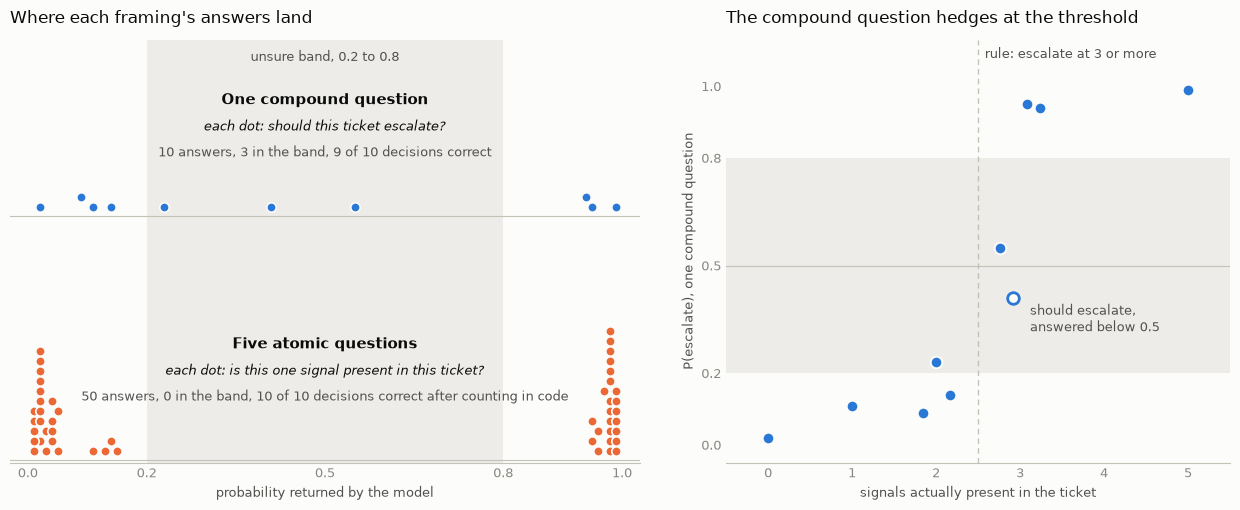

In [ ]:
# Left: every probability each framing returned, with the unsure band shaded. Right: the compound answer against the true signal count.
jevlib.plot_decomposition(dec, signals);

The chart summarises the table: the left panel shows every probability each framing returned, the right panel shows the
compound answer against the true signal count. Read the table by the "signals present" column. Far from the threshold (0, 1 or 5 signals) the single question is
confident and right. At exactly two or three signals it hedges, with answers such as 0.55, 0.41 and 0.23, and it gets one
wrong. The five atomic answers on those same tickets sit near 0 or 1, and the count in code is right every time. Two
further gains: the atomic answers show *which* signals fired, and a bad one can be fixed locally. An earlier wording,
"Is the customer on the enterprise plan?", returned 0.51 when no plan was mentioned; adding the criteria line above
moved it to 0.02. (Ten hand-written tickets illustrate the pattern; they are not a benchmark. An independent phishing
benchmark had Jev at 62.6% as one question and 95.0% as five atomic signals combined by a regression. A simpler rule,
where all of three conditions must hold, showed no gap at all when we tried it: the effect needs counting or weighing.)

---
## 3. Jev vs GPT-6 Luna on CLINC150

CLINC150: 150 intents across 10 assistant domains, crowdsourced single-intent English queries (median 8 words).
The test split has 30 per intent plus 1,000 **out-of-scope** queries that belong to none of the 150.

Each query becomes one `choice` with 150 options. The option descriptions were written from the label names without
looking at test data; both Luna configurations get the identical text (Luna-chat gets it as a system prompt with a
strict JSON enum over the 150 labels).

In [7]:
test, oos = jevlib.load_clinc150()
CRITERIA = json.load(open("data/clinc150_criteria.json"))
assert set(CRITERIA) == set(test.label)
print(f"{len(test)} in-scope test, {len(oos)} OOS, {len(CRITERIA)} intents")
print({k: CRITERIA[k] for k in list(CRITERIA)[:4]})
print("OOS examples:", oos.sample(3, random_state=1).text.tolist())

N_PER_INTENT, N_OOS = 10, 500          # 1,500 in-scope + 500 OOS. Full test set: 30 and 1000.
sample = jevlib.make_sample(test, oos, N_PER_INTENT, N_OOS)
tok = jevlib.est_tokens(CRITERIA) + 60
print(f"~{tok} input tokens/request. Expected spend for 6 passes over {len(sample)} items: "
      f"${sum(tok * len(sample) * 2 * jevlib.PRICE[m]['in'] / 1e6 for m in [JEV, LUNA_DEC, LUNA_CHAT]):.2f}   |   {budget}")

4500 in-scope test, 1000 OOS, 150 intents
{'accept_reservations': 'Does a restaurant take reservations', 'account_blocked': 'Bank account is blocked, frozen, or locked and the user wants to know why or unlock it', 'alarm': 'Set, check, or cancel an alarm', 'application_status': 'Status of a credit card or loan application'}
OOS examples: ['create a speech on historical events surrounding albert einstein', "what do you do all day while i'm at work", 'is the stop sign around the corner still knocked over']
~1894 input tokens/request. Expected spend for 6 passes over 2000 items: $1.83   |   Budget(spent=$0.0000 of $20.00, live calls=0)


In [8]:
CONFIGS = {JEV: False, LUNA_DEC: False, LUNA_CHAT: True}     # model -> use chat completions?
results = {}
for model, chat in CONFIGS.items():
    results[("no_other", model)] = run_batch(model, sample, CRITERIA, "no_other", chat=chat)
budget

  no_other typesafe/jev-1.13: 0/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other typesafe/jev-1.13: 500/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other typesafe/jev-1.13: 1000/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other typesafe/jev-1.13: 1500/2000  Budget(spent=$0.0000 of $20.00, live calls=0)


  no_other openai/gpt-6-luna-decisions: 0/2000  Budget(spent=$0.0000 of $20.00, live calls=0)


  no_other openai/gpt-6-luna-decisions: 500/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other openai/gpt-6-luna-decisions: 1000/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other openai/gpt-6-luna-decisions: 1500/2000  Budget(spent=$0.0000 of $20.00, live calls=0)


  no_other openai/gpt-6-luna: 0/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other openai/gpt-6-luna: 500/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other openai/gpt-6-luna: 1000/2000  Budget(spent=$0.0000 of $20.00, live calls=0)
  no_other openai/gpt-6-luna: 1500/2000  Budget(spent=$0.0000 of $20.00, live calls=0)


Budget(spent=$0.0000 of $20.00, live calls=0)

In [9]:
pd.DataFrame({m: jevlib.summarize(results[("no_other", m)]) for m in CONFIGS}).T

,in-scope acc,macro-F1,invalid / refused,p50 ms,p95 ms,$ / 1k req,mean input tok,ECE (p_max)
typesafe/jev-1.13,"0.951 [0.939, 0.962]",0.951,0,287,408,0.1287,3064,0.022
openai/gpt-6-luna-decisions,"0.935 [0.922, 0.947]",0.929,64,336,588,0.1846,1907,0.023
openai/gpt-6-luna,"0.947 [0.935, 0.957]",0.946,0,1106,1712,0.0305,2200,NaN


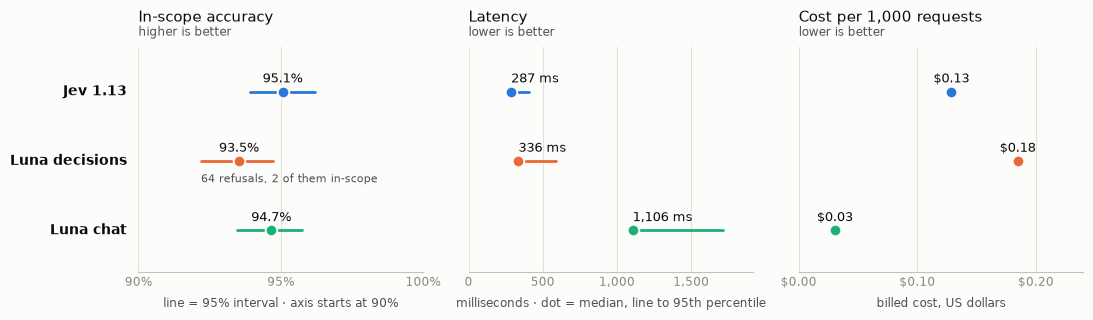

In [ ]:
# The same numbers as a picture: one panel per measure, the same three rows in each.
jevlib.plot_comparison(results, CONFIGS);

What to look at: accuracy within a couple of points of each other, a 3x to 4x latency gap between the decision heads
and chat, and cost per thousand requests. On cost the result cuts against the headline pitch: Luna-chat is the *cheapest*
here, because the 150-line system prompt is identical on every request and OpenRouter bills the cached part at a tenth of
the input rate, while decision models bill every input token every time. Decision models win on price when the state is
large relative to the criteria, or when the criteria change per request; with a long fixed prompt and a short query, a
cached chat prompt wins. There is no ECE for chat because it returns no probability.

The "invalid / refused" column is where the two decision heads differ: Jev always answers, while OpenAI's head can return
a `refusal` (surfaced as an HTTP 502 through OpenRouter), which your code has to treat as a reject.

For scale: OpenRouter's own Banking77 run (77 intents) had Jev 81.0% vs Claude Opus 84.4%, p50 175 ms vs 2,266 ms,
$0.11 vs $2.42 per 1k. A fine-tuned encoder with labelled training data beats all of these; the decision model's case is
zero-shot, cheap, and fast.

---
## 4. Consistency: are the outputs deterministic?

A classifier's probability is only useful if it means the same thing on Tuesday as on Monday. Here each query is sent
ten times to every configuration with the response cache bypassed. Two confident items and three the first pass scored
near 0.5 are taken from section 3's results (so the borderline picks are data-driven, not hand-chosen). Three things
to watch: does the **label** ever change, how much does **p_max** move, and what does chat completions at temperature 0
do on the same items. These calls are not cached, so this cell re-bills (about three cents) on every run.

In [10]:
r = results[("no_other", JEV)]; PROBE_SEED = 3
confident  = r[(~r.is_oos) & (r.p_max >= 0.99)].sample(2, random_state=PROBE_SEED)
borderline = r[(r.p_max > 0.45) & (r.p_max < 0.65)].sample(3, random_state=PROBE_SEED)
probe_items = pd.concat([confident, borderline])
display(probe_items[["text", "label", "pred", "p_max"]])

probe = jevlib.repeat_probe(CONFIGS, probe_items.text.tolist(), CRITERIA, n=10)
pd.set_option("display.max_colwidth", 60)
jevlib.repeat_summary(probe)

,text,label,pred,p_max
1310,how would they say butter in zambia,translate,translate,1.00
1113,what's on my to-buy list,shopping_list,shopping_list,0.99
628,what shall i do now that my battery is dead,jump_start,jump_start,0.50
129,you have yo go to school on calendar,calendar,calendar,0.50
1558,look up articles on the green dry cleaning ind...,oos,definition,0.47


labels seen (count)  \
text                                                model                                                            
how would they say butter in zambia                 openai/gpt-6-luna                               translate (10)   
                                                    openai/gpt-6-luna-decisions                     translate (10)   
                                                    typesafe/jev-1.13                               translate (10)   
look up articles on the green dry cleaning industry openai/gpt-6-luna             travel_suggestion (6), maybe (4)   
                                                    openai/gpt-6-luna-decisions            what_can_i_ask_you (10)   
                                                    typesafe/jev-1.13                              definition (10)   
what shall i do now that my battery is dead         openai/gpt-6-luna                              jump_start (10)   
                                                    openai/gpt-6-luna-decisions                    jump_start (10)   
                                                    typesafe/jev-1.13                              jump_start (10)   
what's on my to-buy list                            openai/gpt-6-luna                           shopping_list (10)   
                                                    openai/gpt-6-luna-decisions                 shopping_list (10)   
                                                    typesafe/jev-1.13                           shopping_list (10)   
you have yo go to school on calendar                openai/gpt-6-luna                                calendar (10)   
                                                    openai/gpt-6-luna-decisions                      calendar (10)   
                                                    typesafe/jev-1.13            calendar_update (7), calendar (3)   

                                                                                 p_max mean  \
text                                                model                                     
how would they say butter in zambia                 openai/gpt-6-luna                   NaN   
                                                    openai/gpt-6-luna-decisions       0.460   
                                                    typesafe/jev-1.13                 1.000   
look up articles on the green dry cleaning industry openai/gpt-6-luna                   NaN   
                                                    openai/gpt-6-luna-decisions       0.230   
                                                    typesafe/jev-1.13                 0.425   
what shall i do now that my battery is dead         openai/gpt-6-luna                   NaN   
                                                    openai/gpt-6-luna-decisions       0.820   
                                                    typesafe/jev-1.13                 0.474   
what's on my to-buy list                            openai/gpt-6-luna                   NaN   
                                                    openai/gpt-6-luna-decisions       0.770   
                                                    typesafe/jev-1.13                 0.990   
you have yo go to school on calendar                openai/gpt-6-luna                   NaN   
                                                    openai/gpt-6-luna-decisions       0.950   
                                                    typesafe/jev-1.13                 0.497   

                                                                                    sd  \
text                                                model                                
how would they say butter in zambia                 openai/gpt-6-luna              NaN   
                                                    openai/gpt-6-luna-decisions  0.000   
                                                    typesafe/jev-1.13            0.000   
look up articles on th

What this shows, and what independent repeats of the same probe have shown:

* **Jev is not deterministic.** Identical requests return probabilities that differ by a few hundredths (TypeSafe's own
  consistency cookbook reports a standard deviation near 0.01; third-party repeats see 0.03 to 0.04, and up to 0.13 on hard
  data). On confident items the label never moves. On a borderline item with two options near 0.45 the label can flip
  between calls, which is exactly where a naive threshold would sit.
* **OpenAI's decision head is repeatable within a session, not across days.** In each run its ten repeats were
  identical or within 0.01, borderline items included, and no label moved. But the same five queries run two days apart
  gave different values (0.85 then 0.77 on one, 0.74 then 0.82 on another), and one label changed. So "identical on
  repeat" may reflect something like short-lived server-side reuse or a model update between runs; we cannot tell which
  from outside. It can also disagree with the *same model* called through chat completions on the same input.
* **Chat completions at temperature 0 are greedy, not deterministic.** The label can flip between repeats on ambiguous
  items, and because no probability comes back there is no way to see that the answer was a coin toss.
* **Repetition is the small source of variance.** Reordering options or rewording criteria moves answers far more than
  calling again does (one audit saw 28% of answers change on reorder; a pre-registered study saw up to 13 points on
  ambiguous tasks). Test those, not just repeats.

Practical rule: treat a decision-model probability as having error bars of a few hundredths, and never place a threshold
where a 0.47 versus 0.45 split decides an action.

**Across days.** The same queries were sent to OpenAI's decision head on four separate days. Within any one day the ten
repeats were identical. Across days the values stepped once, between 11 and 13 October, and one label changed:

| query | 10 Oct | 11 Oct | 13 Oct | 15 Oct |
|---|---|---|---|---|
| what's on my to-buy list | | shopping_list 0.85 | shopping_list 0.77 | shopping_list 0.77 |
| you have yo go to school on calendar | calendar 0.94 | calendar 0.94 | calendar 0.95 | calendar 0.95 |
| what shall i do now that my battery is dead | jump_start 0.74 | jump_start 0.74 | jump_start 0.82 | jump_start 0.82 |
| how would they say butter in zambia | | definition 0.49 | translate 0.46 | |
| look up articles on the green dry cleaning industry | what_can_i_ask_you 0.25 | what_can_i_ask_you 0.25 | what_can_i_ask_you 0.23 | |

Every response on every day reported the same model version, `gpt-6-luna-decisions-20261006`, so the shift was not
signalled by the version string. Whether it came from OpenAI, from OpenRouter's routing, or from deliberate server-side
behaviour cannot be told from outside. Luna chat split its answer on the out-of-scope query on every day it was run
(7 to 3, 8 to 2, 6 to 4 between `maybe` and `travel_suggestion`). Blank cells are queries a run did not include; the 10 and
15 October values come from separate small runs outside this notebook, so this cell is a record, not something it regenerates.

The practical point: pinning a model name does not guarantee identical outputs over time. If thresholds are tuned on one
week's results, re-check them on a small fixed set of queries like these, because a silent shift of 0.08 is enough to move
an answer across a threshold.

---
## 5. The unknown-category problem

### 5.1 Without `other`: 500 off-topic queries, 150 options

By construction every OOS query received one of the 150 intents (or, for OpenAI's head only, a refusal). The only
other signal is a lower probability. How well does `p_max` separate OOS from in-scope, and how confident are the misfiles?

,"refused, OOS / in-scope",AUROC of p_max as OOS detector,"median p_max, in-scope","median p_max, OOS",OOS misfiled at p_max >= 0.9,OOS misfiled at p_max >= 0.99,note
typesafe/jev-1.13,0.0% / 0.0%,0.928,1.0,0.58,17.2%,5.0%,NaN
openai/gpt-6-luna-decisions,12.4% / 0.1%,0.954,0.99,0.235,4.6%,0.9%,NaN
openai/gpt-6-luna,NaN,NaN,NaN,NaN,NaN,NaN,"chat completions: no probability, no signal at..."


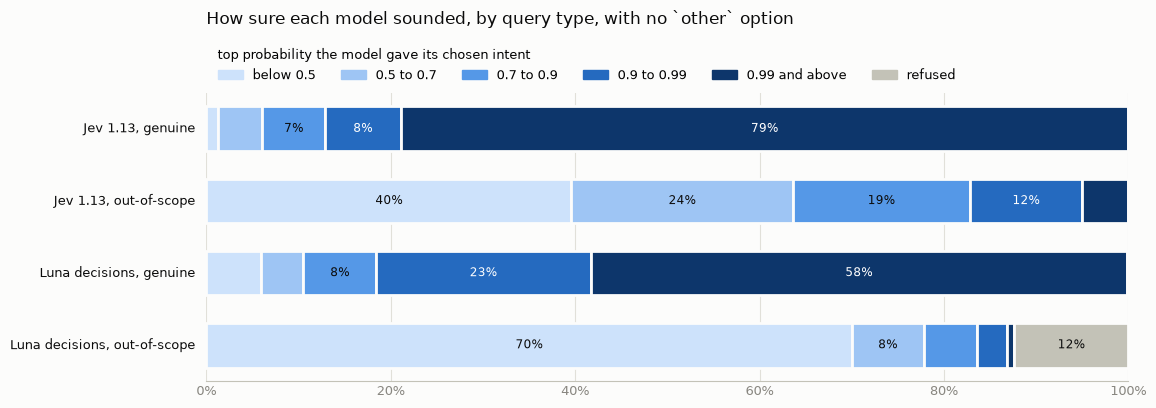

In [11]:
from sklearn.metrics import roc_auc_score

def oos_report(res):
    r = res.dropna(subset=["p_max"])
    if r.empty: return {"note": "chat completions: no probability, no signal at all"}
    o = r[r.is_oos]
    return {"refused, OOS / in-scope": f"{res[res.is_oos].pred.isna().mean():.1%} / {res[~res.is_oos].pred.isna().mean():.1%}",
            "AUROC of p_max as OOS detector": round(roc_auc_score(r.is_oos, -r.p_max), 3),
            "median p_max, in-scope": round(r[~r.is_oos].p_max.median(), 3),
            "median p_max, OOS": round(o.p_max.median(), 3),
            "OOS misfiled at p_max >= 0.9": f"{(o.p_max >= 0.9).mean():.1%}",
            "OOS misfiled at p_max >= 0.99": f"{(o.p_max >= 0.99).mean():.1%}"}

display(pd.DataFrame({m: oos_report(results[("no_other", m)]) for m in CONFIGS}).T)

# Each bar splits one model's queries by how sure it sounded. Darker = more confident; grey = refused.
jevlib.plot_confidence_bands(results, [JEV, LUNA_DEC]);

**Reading the chart.** Every out-of-scope query here was either given one of the 150 intents or, for OpenAI's head
only, refused: there was no "none of these" to choose. The bars show how confident those wrong answers sounded. For genuine
queries both models are mostly at 0.99 and above, which is what you want. For out-of-scope queries the picture splits: Luna's
decision head sounds unsure about most of them (70% below 0.5) and refuses another 12%, while Jev answers them across the
whole range, with 40% below 0.5 but 17% at 0.9 or above. Those high-confidence misfiles are the real risk: they look exactly
like correct answers, so a confidence threshold alone will not catch them. Low probability is a useful warning sign, but
the reliable fix is to give the model an explicit `other` option, which section 5.2 tests.

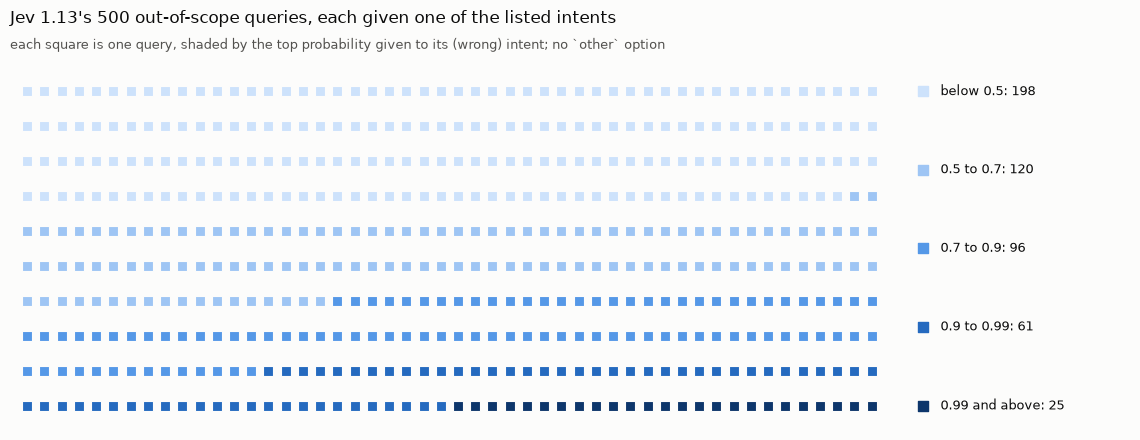

In [ ]:
# The same result for Jev, one square per out-of-scope query.
jevlib.plot_unknown_squares(results, JEV);

<details>
<summary><b>What this chart shows</b></summary>

Each square is one of the 500 off-topic queries sent to Jev. With no "none of these" option, every one was filed under one
of the 150 intents, shaded here by how sure Jev sounded. The 86 darkest squares, about one in six, were filed at a
probability of 0.9 or higher, the same confidence Jev shows on most genuine queries, so nothing in the answer marks them
as wrong.
</details>

In [12]:
# The most confident misfiles. (A pre-registered study saw a cake recipe routed as a technical issue at 0.94.)
r = results[("no_other", JEV)]
r[r.is_oos].sort_values("p_max", ascending=False)[["text", "pred", "p_max"]].head(10)

,text,pred,p_max
1500,find directions to the sunshine car wash from my house,directions,1.0
1718,what is one standard deviation,definition,1.0
1889,when's the next mardi gras going to be,next_holiday,1.0
1568,where's the best place to hike in the rockies,travel_suggestion,1.0
1861,look up the average temperature changes over the last 30...,weather,1.0
1813,is there a vaccine for ebola,vaccines,1.0
1600,can you tell me the purpose of a safe deposit box,definition,1.0
1606,who has the longest hair ever,fun_fact,1.0
1785,forward the text i just got from henry to giselle,text,1.0
1916,inform me of what microbes are,definition,1.0


### 5.2 With `other`: does an escape hatch fix it?

Add a 151st option, `other`. Three numbers per model:

* **OOS caught**: share of OOS queries routed to `other`.
* **False `other`**: in-scope queries wrongly sent to `other` (the price of the fix).
* **Still confidently wrong**: OOS queries given a real intent at `p_max >= 0.9` even though `other` was available.

Published evidence predicts partial success. One probe: Jev answered 47% of unanswerable items confidently without an
abstain option; with one, 77% abstained but 13% still answered confidently. The LLM literature (Tam et al. 2025, 28
models) shows 30 to 50 point drops when "none of the above" is the right answer, so Luna is not expected to be immune.

In [13]:
CRITERIA_OTHER = {**CRITERIA, "other": "None of the listed intents fits this message, or it is off-topic for this assistant"}
for model, chat in CONFIGS.items():
    results[("with_other", model)] = run_batch(model, sample, CRITERIA_OTHER, "with_other", chat=chat)
budget

  with_other typesafe/jev-1.13: 0/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other typesafe/jev-1.13: 500/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other typesafe/jev-1.13: 1000/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other typesafe/jev-1.13: 1500/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other openai/gpt-6-luna-decisions: 0/2000  Budget(spent=$0.0174 of $20.00, live calls=150)


  with_other openai/gpt-6-luna-decisions: 500/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other openai/gpt-6-luna-decisions: 1000/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other openai/gpt-6-luna-decisions: 1500/2000  Budget(spent=$0.0174 of $20.00, live calls=150)


  with_other openai/gpt-6-luna: 0/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other openai/gpt-6-luna: 500/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other openai/gpt-6-luna: 1000/2000  Budget(spent=$0.0174 of $20.00, live calls=150)
  with_other openai/gpt-6-luna: 1500/2000  Budget(spent=$0.0174 of $20.00, live calls=150)


Budget(spent=$0.0177 of $20.00, live calls=151)

In [14]:
def other_report(res):
    o, i = res[res.is_oos], res[~res.is_oos]
    row = {"OOS caught by 'other'": f"{o.pred.eq('other').mean():.1%}",
           "in-scope falsely 'other'": f"{i.pred.eq('other').mean():.1%}",
           "in-scope accuracy": f"{i.pred.eq(i.label).mean():.1%}"}
    if res.p_max.notna().any():
        row["OOS still given an intent at p_max >= 0.9"] = f"{(~o.pred.eq('other') & (o.p_max >= 0.9)).mean():.1%}"
    return row

pd.DataFrame({m: other_report(results[("with_other", m)]) for m in CONFIGS}).T

,OOS caught by 'other',in-scope falsely 'other',in-scope accuracy,OOS still given an intent at p_max >= 0.9
typesafe/jev-1.13,92.2%,3.1%,93.1%,2.2%
openai/gpt-6-luna-decisions,95.6%,7.7%,88.9%,1.0%
openai/gpt-6-luna,94.2%,3.7%,93.3%,NaN


In [15]:
# Before vs after, side by side
pd.DataFrame({m: {"in-scope acc, no other":   results[("no_other", m)].pipe(lambda r: r[~r.is_oos].pipe(lambda i: i.pred.eq(i.label).mean())),
                  "in-scope acc, with other": results[("with_other", m)].pipe(lambda r: r[~r.is_oos].pipe(lambda i: i.pred.eq(i.label).mean())),
                  "OOS caught, no other": 0.0,
                  "OOS caught, with other":   results[("with_other", m)].pipe(lambda r: r[r.is_oos].pred.eq("other").mean())}
              for m in CONFIGS}).T.round(3)

,"in-scope acc, no other","in-scope acc, with other","OOS caught, no other","OOS caught, with other"
typesafe/jev-1.13,0.951,0.931,0.0,0.922
openai/gpt-6-luna-decisions,0.935,0.889,0.0,0.956
openai/gpt-6-luna,0.947,0.933,0.0,0.942


**A note on refusals.** OpenAI's decision head sometimes returns a refusal instead of an answer (OpenRouter surfaces it as
an HTTP 502 saying "OpenAI refused to answer question"). Jev never does. The cell below shows these are mostly *not*
content-safety refusals: nearly all of them vanish once `other` is offered, and the same queries are answered `other`
instead. A safety filter would not care whether an escape option exists; a model declining because nothing fits would
behave exactly like this. So the refusal is a built-in, but weak, "none of these" signal: it fired on about an eighth of
out-of-scope queries, and the rest were still given an intent. The refused queries are mostly harmless ("how do you unclog
a toilet", "what is the current price of tsla"). The reason for a refusal is not passed through, so this reading is inferred
from behaviour. Whatever the cause, code has to treat a refusal as a reject.

In [ ]:
a, b = results[("no_other", LUNA_DEC)], results[("with_other", LUNA_DEC)]
ra, rb = a[a.pred.isna()], b[b.pred.isna()]
display(pd.DataFrame({"refused": [len(ra), len(rb)], "out-of-scope": [ra.is_oos.sum(), rb.is_oos.sum()], "in-scope": [(~ra.is_oos).sum(), (~rb.is_oos).sum()]},
                     index=["150 options, no `other`", "151 options, with `other`"]))
again = b.set_index("text").loc[ra.text].pred.fillna("refused again").value_counts()
print(f"The {len(ra)} queries refused without `other` were answered, with it:", again.to_dict())
print("Still refused with `other`:", rb.text.tolist())
print("Refused in-scope queries:", ra[~ra.is_oos].text.tolist())

,refused,out-of-scope,in-scope
"150 options, no `other`",64,62,2
"151 options, with `other`",1,1,0


The 64 queries refused without `other` were answered, with it: {'other': 63, 'refused again': 1}
Still refused with `other`: ["what's the best way to drown a witch"]
Refused in-scope queries: ["what's the pin number for my checking account", 'lost report card, need new one']


### 5.3 A threshold as the second line of defence

The residue that still gets a real intent is the dangerous part: it looks exactly like a good answer. The decision head
gives you something chat completions cannot: a number to threshold. Rejecting anything with `p_max` below *t* (sending it
to a person or a fallback) trades in-scope coverage for OOS protection.

In [16]:
def sweep(res, ths=(0.5, 0.7, 0.8, 0.9, 0.95, 0.99)):
    rows = []
    for t in ths:
        reject = (res.p_max < t) | res.pred.eq("other") | res.pred.isna()     # invalid/refused answers also go to fallback
        rows.append({"threshold": t,
                     "OOS rejected": reject[res.is_oos].mean(),
                     "in-scope rejected": reject[~res.is_oos].mean(),
                     "acc on accepted in-scope": res[~res.is_oos & ~reject].pipe(lambda d: d.pred.eq(d.label).mean())})
    return pd.DataFrame(rows).set_index("threshold").round(3)

pd.concat({m: sweep(results[("with_other", m)]) for m in [JEV, LUNA_DEC]}, axis=1)

typesafe/jev-1.13                                             \
               OOS rejected in-scope rejected acc on accepted in-scope   
threshold                                                                
0.50                  0.928             0.048                    0.967   
0.70                  0.964             0.099                    0.979   
0.80                  0.966             0.118                    0.983   
0.90                  0.978             0.155                    0.987   
0.95                  0.980             0.197                    0.991   
0.99                  0.988             0.255                    0.993   

          openai/gpt-6-luna-decisions                    \
                         OOS rejected in-scope rejected   
threshold                                                 
0.50                            0.964             0.096   
0.70                            0.970             0.132   
0.80                            0.982             0.153   
0.90                            0.990             0.187   
0.95                            0.990             0.235   
0.99                            0.992             0.369   

                                    
          acc on accepted in-scope  
threshold                           
0.50                         0.971  
0.70                         0.980  
0.80                         0.983  
0.90                         0.985  
0.95                         0.987  
0.99                         0.992

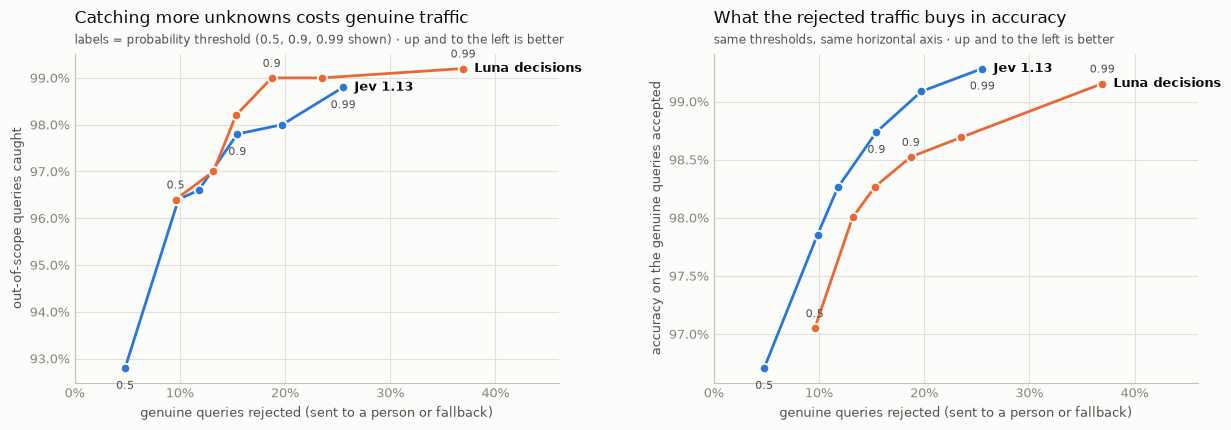

In [ ]:
# The sweep table as a trade-off curve. Luna chat is absent: it returns no probability to threshold.
# Scored on the same queries it sweeps over, so this shows the shape of the trade-off, not a threshold ready to deploy.
jevlib.plot_tradeoff(results, CONFIGS);

---
## 6. Take-aways

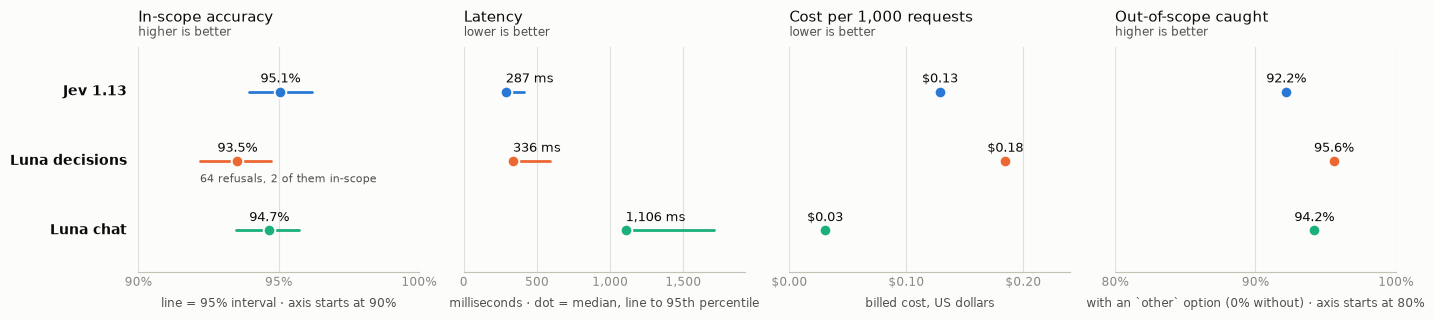

In [ ]:
# Summary figure: the section 3 comparison plus out-of-scope queries caught once `other` is offered.
jevlib.plot_comparison(results, CONFIGS);

**A decision model is a different interface, not a cheaper LLM.** Typed questions in, probabilities out, no text. The
probability is the product: it is what lets code decide to act, confirm, or escalate.

**The criteria are the program.** Descriptions matter more than names, option order can move answers, and narrow
questions combined in code beat one broad question.

**On accuracy, cost, latency.** Section 3's table is the comparison to quote: all three within a couple of points on
accuracy, the decision heads 3x to 4x faster than chat, and, with a long fixed prompt, cached chat completions cheaper per
thousand than either decision model. Jev is the cheapest decision model; price it against your own state size, not the
list rate.

**On unknown input.** The schema guarantees a well-formed answer, not a correct one. Without `other`, every off-topic
query that was not refused received one of the 150 intents, and a sizeable share of those at p_max of 0.9 or more
(section 5.1). OpenAI's head refused about an eighth of the OOS queries, which is a weak unknown detector in its own
right. With `other`, 92% to 96% of OOS was caught, at a cost of 2 to 5 points of in-scope accuracy, and a residue was still
assigned a real intent at high confidence on both decision heads (section 5.2). A probability threshold on top catches most
of that residue in exchange for routing 10% to 25% of in-scope traffic to a fallback (section 5.3). Production use needs all
three: an explicit `other`, a threshold tuned on your own labelled data, and ideally a relevance `noul` in front.

**What Jev is bad at**, per TypeSafe's own notes: counting, dates, arithmetic, double negatives, large or irrelevant
state, injected instructions in the state, and a lean toward the first option. Nearly all third-party Jev numbers are
single runs from the last few weeks; TypeSafe's own accuracy claims measure agreement with two frontier LLMs, not truth.

**Possible next steps.** Full test set (`N_PER_INTENT=30, N_OOS=1000`); in-domain OOS by holding 15 intents out of the
option list (far-OOS like recipes is the easy case); a second decision model from the catalog (`inception/mercury-decide:free`
is free); a prompt-injection probe.